# IRL Models

- saves `irl_models/models_integrated.csv` from `data/data_integrated.csv`

## Setup

Import libraries.

In [137]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_rel

from utils_irl_models import load_trained_model, load_connected_traj, calculate_action_prediction_performance

### Util

In [138]:
import re

disc_acc_pattern = re.compile(r"Round\s+(\d+)\s+\|\s+disc_acc=([\d.]+)\s+\|\s+disc_acc_expert=([\d.]+)\s+\|\s+disc_acc_gen=([\d.]+)")
def extract_disc_acc_metrics(subj_id, round):
    with open(f"irl_models/{subj_id}/rewnet_8_8_best/README.md", "r") as f:
        for line in f:
            match = disc_acc_pattern.search(line)
            if match:
                round_num = int(match.group(1))
                if round_num == round:
                    return {
                        "subj_id": subj_id,
                        "model_type": "rewnet_8_8",
                        "rounds": round_num,
                        "disc_acc": float(match.group(2)),
                        "disc_acc_expert": float(match.group(3)),
                        "disc_acc_gen": float(match.group(4)),
                    }
    return None

## Data

In [139]:
df = pd.read_csv("data/data_integrated.csv", encoding="utf-8-sig")
print(f"N={len(df)}")
df.head()

N=282


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_high_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_total_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_easy_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_hard_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_low_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha,web
0,904,22,1,73,23,31,19,-1,87,44,...,91,21,3,18,4,3,14,-3.272599,0.347513,False
1,1000,32,2,61,18,22,21,-1,84,38,...,26,22,2,20,7,8,7,-6.330838,0.660547,False
2,1001,25,2,73,20,31,22,-1,77,38,...,3,14,2,12,2,6,6,-7.961866,0.612792,False
3,1002,21,2,63,22,22,19,-1,73,38,...,64,28,2,26,11,13,4,-1.564452,1.412119,False
4,1003,26,2,69,22,24,23,-1,86,40,...,13,46,2,44,13,16,17,-5.378190,0.668441,False


## Trained Models

In [140]:
models = []
all_subj_ids = set()
for pair in [
    # Desktop sample (subj_id, rounds)
    [904, 11600],
    [1000, 18980],
    [1001, 18580],
    [1002, 18080],
    [1003, 18220],
    [1004, 18360],
    [1005, 12950],
    [1006, 13950],
    [1007, 39550],
    [1008, 17760],
    [1009, 13980],
    [1010, 7230],
    [1011, 5480],
    [1012, 15350],
    [1013, 13660],
    [1014, 18150],
    [1015, 5460],
    [1017, 17490],
    [1018, 12720],
    [1019, 11760],
    [1020, 7180],
    [1021, 15230],
    [1023, 10700],
    [1024, 16590],
    [1025, 19750],
    [1026, 14350],
    [1027, 12610],
    [1028, 14740],
    [1029, 15510],
    [1030, 17650],
    [1031, 17380],
    [1032, 19580],
    [1033, 15860],
    [1034, 13990],
    [1035, 18940],
    [1036, 19890],
    [1037, 6640],
    [1038, 17910],
    [1039, 17040],
    [1040, 19940],
    [1041, 7040],
    [1042, 12780],
    [1043, 19120],
    [1044, 19410],
    [1045, 4320],
    [1046, 18730],
    [1047, 8380],
    [1048, 13260],
    [1049, 10260],
    [1050, 8160],
    [1052, 14510],
    [1053, 6850],
    [1054, 18610],

    # Web sample (subj_id, rounds)
    ["69d2b8672541083658fc0f45", 19500],
    ["69baa37ab3cd7666686359dd", 12450],
    ["6914ee600a780033d4f42beb", 13880],
    ["5a91756d6475f900019f90f1", 17220],
    ["69669bf59af686ae3725bce8", 14740],
    ["67ad581c7825ebbd7a5365e0", 18400],
    ["6298f0e21abd78cb684b723c", 16240],
    ["6650a38d75c08f70233642b1", 12040],
    ["66c8abe49537b182dcbd2049", 13880],
    ["5eb15429b3b24804a0bbd6c3", 18990],
    ["5d014a5dcd2e40001827abde", 16200],
    ["67c869872204b85d6c4c0749", 16540],
    ["69d1b9a8e219f805edff584a", 18010],
    ["5f9fdfd04296cb0102563f84", 16290],
    ["69cb8bf56b4681853352046a", 17640],
    ["69cc1a3e3df02a2a908f9d5f", 14620],
    ["69bf627b9c8841218fe9abee", 4930],
    ["5c0676a61a20110001ea1a24", 1920],
    ["6631300c50bd0ffe1e8cd586", 18620],
    ["5ba78b71d60daf0001532d5b", 17900],
    ["69c8f3b004d0bc57c8228a6b", 14660],
    ["62a89318448a8592fc88ee03", 14630],
    ["69aa1a18ac78b4ee46076875", 6880],
    ["606f9bca353fc36aba9ccb8b", 18620],
    ["69b62c6bbde27e7b746a47d4", 9190],
    ["69c6c4ca00c8075f7c348c50", 10470],
    ["6970cdebc8c497d744a5381d", 7520],
    ["6742cee9f00d7e803911c6db", 12000],
    ["6988db1e98668b7f6151a2d6", 7790],
    ["5753046ba6deb50006d64b0f", 11080],
    ["6234c1abfc04a4163c09a78f", 8520],
    ["69c6b49032de4e6462fd0792", 19560],
    ["646ff124ef129159bf5f08f7", 14890],
    ["69b17c7689a785042933f7fb", 10160],
    ["6978e1adc498760963a10b9c", 13870],
    ["5c04872c55614800012b7cf0", 8440],
    ["60fcebba7345a976efc9c080", 10960],
    ["6988affdda027fa76c688e1a", 19900],
    ["69a48ff048b63493319264be", 18500],
    ["5d88db42c1d06e001a1fdcab", 10330],
    ["69baa27614b2c61d994a5fcc", 14940],
    ["698ccd223026f8fb4c8884d3", 27200],
    ["69a9fd65e7edaf2adf755689", 17960],
    ["69cff96f804a6ced14cb87d1", 19960],
    ["69bb7c753d4d053eff9c692b", 19220],
    ["675c6db4887ccdd0d3d15534", 12680],
    ["69c8053e8f584e930c1722b1", 18540],
    ["69b88fbfb1df7d2b9f369cb7", 11520],
    ["6941ab4f0423e9fd1598fdf1", 10810],
    ["60f3c1b003bbf8263f002824", 19500],
    ["59db7128e776fd00015ec895", 17840],
    ["69b9dc367fe8a0f25c27fd3e", 11180],
    ["668a6f07c623b9b9500b962f", 15550],
    ["6296bef3248bf76cc113926b", 17960],
    ["66045b60e84f1f2485dc2a4a", 12000],
    ["62951acd624dba0f4429d988", 18850],
    ["6965ba772b55e614116e4954", 13650],
    ["696948c21cc706a65dd5014e", 19550],
    ["55b3120cfdf99b6ef6263a71", 17880],
    ["6969488b673aca094759706d", 11220],
    ["69be9a4e9703883728f08969", 17900],
    ["663a7dc83986ee24fb6ec0e6", 17800],
    ["69c8beea57382d592daa0629", 16410],
    ["5f57c1f5ebda262c8446916e", 18000],
    ["698e420735e53080e135f8b8", 12190],
    ["699cc370297ac399dc12e868", 9340],
    ["66594968a8fca6ea85c9ac19", 11250],
    ["69cbeee63cec140ffaaeb8ba", 16100],
    ["67612c302f90b2399522a2ba", 7820],
    ["69cb5a7d7de2219df5c8c239", 19350],
    ["6978b16217b05571dd3dd0fd", 13050],
    ["69b0cfe7076b7ef983adc570", 11500],
    ["69991d70dd2583a349d03468", 19210],
    ["69c445bec8c8b5ec65ca2087", 13680],
    ["66116b402e87c03e47d1d74c", 6480],
    ["695fed791a1d6de6d0a812da", 14650],
    ["65e5ec7c5cc8e775d79139b5", 15860],
    ["5c3c1617f5ebd500018596cb", 6080],
    ["5d96eeed1998fb00177f6b71", 16530],
    ["69c8ae928efe7ba1a388f43d", 18130],
    ["69d08126206d6fbc9c2392b1", 16090],
    ["666f76b68b89442817be678a", 15680],
    ["699ec1b07f864a863c6f1740", 19980],
    ["6687a66faa865642f33dc043", 7580],
    ["69b4825aaba429c7d8b74998", 18460],
    ["69977f5b94c33ffb8f4222a6", 14790],
    ["699f3d1a77d51612aeaf5766", 19710],
    ["6989471ad0c44d2fb312cbe1", 16710],
    ["66a3279007dbdd4d6d3a64a7", 4970],
    ["6996589ef8807b43043aef11", 12220],
    ["69af9cfa02fcdbbb9eae4b3f", 9670],
    ["697cd720a414418e49c8d1e7", 17890],
    ["69a0a500dbbe6fc2a5c5c04c", 17810],
    ["63f794e7d8d24753edbbb136", 12510],
    ["5adf6ea7f6b58c0001fa8404", 8900],
    ["6943fe6c76afd417a50bc5b3", 19040],
    ["6154973c69da7c97996a19f6", 18320],
    ["69cf29a1158121b176bb8c80", 16300],
    ["69bec22075d6184e7fd70364", 14610],
    ["63e548363c6296f44832c59c", 19330],
    ["6705bf2688ed88bcafd57446", 16530],
    ["6710a253716dc387be084076", 16940],
    ["69bb18d1d2a81dcf52c22b0f", 7410],
    ["6314c1e76c3f71e2127f1976", 19930],
    ["655b67f729177b2ec81552b3", 19930],
    ["61647de75314468d5cb57f93", 19520],
    ["64d525cf660422c33e465cf4", 4870],
    ["611842195ebcbb197bc11c0e", 10750],
    ["5df861926aab7c5f659dfd85", 10740],
    ["673e5fc42cbf961c153d09d3", 16100],
    ["699fb907e53c96eba2226ff3", 13570],
    ["6752993adafe95d86087831b", 19490],
    ["69b831c2af3d139725f769f1", 5910],
    ["668512ccce74ea87cbdd72de", 5370],
    ["6150a7aff22eb4723de2341a", 11070],
    ["69b164d40e7015d13a00818e", 5980],
    ["603c30cc6aac099ca7f0b6b9", 9990],
    ["69cfd3a8dc59402e42230ced", 17270],
    ["69a2225ebe9ce7db75c5cee5", 5160],
    ["63474e67a5fd298c6103c409", 18310],
    ["699a33aafbd53b2aec59393f", 9460],
    ["69c2f3987fe5107641f6b223", 13660],
    ["6942f32ddfdc9e594f10ab59", 16000],
    ["5c6071a1e1df700001ca8bf1", 8620],
    ["6996592ef020a09f22cb6306", 15520],
    ["5a443812817d1800018d1179", 19190],
    ["5be8dab5d153f500019ab320", 17000],
    ["6980e3e9098d36808e97bd79", 14430],
    ["69419e9576aea13f332266ff", 19180],
    ["69c5abf52ce23326bc9c25ca", 15560],
    ["62c0e760fe5cc4964a774900", 9380],
    ["69c5d21edb1054599e74d625", 9600],
    ["6993ca827feb9f82e8f22cd2", 12130],
    ["6982683649f1df41ba7a5505", 18030],
    ["69cc19a2449f9d4df4a878d6", 18480],
    ["67df2438f087a74ea30f779b", 8920],
    ["699ca57afe02c2af2c2347d1", 19270],
    ["66a428de01ccbc61556d585b", 19130],
    ["66b2c7262f4631f5eea8e729", 16130],
    ["697cbf945c186a9071d752fd", 19330],
    ["6985e73e501c4df376a58abf", 16190],
    ["696080f271b010ddcd31caa6", 13300],
    ["5fb156d6e16ee65ed2558d7c", 16490],
    ["675ce427f72ea526d6083376", 7790],
    ["5f0a686635f72917e94c7a63", 8520],
    ["695fc4e377dae78868cec1d5", 17170],
    ["6562177a48308eebbb6359ea", 17270],
    ["67b746fca75ce7e982a23c67", 15480],
    ["678c89e7d72ecd785f475dfd", 13530],
    ["69cd6dcab3ca40a15e9281c3", 7820],
    ["67f192e08cf17c568074969d", 18520],
    ["5e07a0898dffa00ff1aaf60f", 19050],
    ["6942a793a0943732e26bc8a2", 23200],
    ["5eace152e25d6800091dd418", 14930],
    ["67ddd4f85ab870ffd90cc888", 13650],
    ["69b427f00b20c23eb7bd2bea", 8640],
    ["69c1a6156cb375150fb5dfdb", 11810],
    ["66294c688bad7715018bfd57", 17330],
    ["668edb3b608a3d4537e2da08", 18480],
    ["62dc3847e0742087b3033fe5", 9470],
    ["69ca0358aceca179f5e50eaf", 12290],
    ["6942c05a7a01b8119deb4a9c", 11720],
    ["69ba5673807ffc7a9c6618cc", 23410],
    ["669424e6b661e0a098ec66a4", 9550],
    ["615dd0b0a024ba4f4b4f7c24", 11200],
    ["67ac5678d6ff3c43d30b333f", 12920],
    ["60fdb73b85f276ed91d84eb9", 29450],
    ["69864995ddacce2029a50fe2", 19130],
    ["69bc413db3462e13d3f11e29", 19870],
    ["6786abc3a98055356d70eb64", 13270],
    ["65dcea3d5bd259328f538247", 19300],
    ["67e1da8a432675c0e850e8d1", 17270],
    ["699639261d37728e7e93d15d", 13290],
    ["663cc8df4e65d79a540bed2e", 16960],
    ["6992e04a1733a51d3579b194", 18680],
    ["6630e75a1f3d3083c3fd00fc", 13380],
    ["5c01d3c509e9c70001500b10", 13060],
    ["60fee1a0234ddea6fd998ba0", 11560],
    ["5b50881a59119400018abaf3", 8700],
    ["66aa8d04719b0f5ef3433e9c", 6110],
    ["66db9db4324609f1a7231f49", 16730],
    ["69a9e5bf591680851043ed1c", 10810],
    ["69adf185dcc8cda73749368d", 15370],
    ["616f727b03e888e0f8213eec", 19790],
    ["663ff3e539df6ec6f060f875", 9550],
    ["67299a3cb9242638dd2556db", 19460],
    ["69936eccf50fa8ffd94e8b4e", 10660],
    ["67f1626e4525cfea0f0a9753", 16010],
    ["69bd4d62d82d36ce83965038", 16690],
    ["665145fa2cef092b90f2f1d0", 11340],
    ["677fea44f0780e29406c0f6a", 7120],
    ["66eb1a41306925cf993d6490", 10990],
    ["699293129f0baf693f34d7db", 18610],
    ["69b98c628f8e8a390c8ed62f", 18660],
    ["67f1f1d53b5c101545b04cfc", 12180],
    ["69c58ffd18c4c49927581384", 19440],
    ["6978bda2039ef7c2454998b0", 11070],
    ["69bc777e18109fd8376427b0", 18780],
    ["66463d8b1984a328f78252d7", 19410],
    ["67b8d3adc925460632e8e8a1", 18200],
    ["58ed2be2a083320001a13783", 18550],
    ["69c242378782e2084568d7b2", 9250],
    ["66b3e078bef7d6dd6c53e015", 13630],
    ["6938b3a102d6dfae6c72a140", 19890],
    ["66f26de8c801a62c5db9e718", 16190],
    ["5654171504212700054a12ad", 21310],
    ["5e83abb4e0a2e40fd565226d", 7690],
    ["69c0fcabd999cc90c91fbb5d", 13530],
    ["67b8f459f36ac348b98d6cad", 15650],
    ["62d43cee3d60ac98c1dcacc8", 18700],
    ["69864918d688ba39aab5c4a9", 7760],
    ["69b37d42378c672c56abb20b", 7720],
    ["6746c680672c3ab45f25efb7", 16020],
    ["699f61cee0a20b342f6f4b00", 9350],
    ["69bda160389f655c9db99884", 19190],
    ["69932ccc26c39ba9a7a39642", 16020],
    ["695fb9573cce970ab9ff4a87", 8360],
    ["652d8afc5aaab078ef2baeb3", 9460],
    ["66465c850d9a3e177f2649fa", 9300],
    ["6998fd41ff6a5eb792f085d6", 16310],
    ["69c55632a9601c06a96388b9", 12550],
    ["60cc67809f92d570ba4dc2c5", 19080],
    ["663cca6f32da191e05406d21", 7820],
    ["608bfa04767191aa4d57bfd8", 13010],
    ["5f1e363c0add987ddec0faa8", 19550],
    ["60fa23798a416fb0d9e4ec76", 10560],
    ["67f2b914d702155cbc0a3a2c", 9050],
    ["66f0c2c17d872e5874877985", 18850],
    ["66d1fdd400acfdbc181f41e0", 14170],
]:
    subj_id, rounds = pair
    sample_type = "desktop" if type(subj_id) == int else "web"
    subj_id = str(subj_id)
    if subj_id in all_subj_ids:
        raise Exception(f"duplicate {subj_id} found")
    all_subj_ids.add(subj_id)
    models.append({
        'subj_id': subj_id,
        'sample_type': sample_type,
        'rounds': rounds,
    })

valid_subj_ids = set(df["subj_id"])
if all_subj_ids == valid_subj_ids:
    print("all the valid subjects are included")

print(f"N={len(models)}")
df_models = pd.DataFrame(models)

df_models.head()

all the valid subjects are included
N=282


,subj_id,sample_type,rounds
0,904,desktop,11600
1,1000,desktop,18980
2,1001,desktop,18580
3,1002,desktop,18080
4,1003,desktop,18220


## Model Evaluation

### Discriminator Accuracy

In [141]:
for col in ["disc_acc", "disc_acc_expert", "disc_acc_gen"]:
    if col not in df_models.columns:
        df_models[col] = np.nan

df_models.head()

,subj_id,sample_type,rounds,disc_acc,disc_acc_expert,disc_acc_gen
0,904,desktop,11600,NaN,NaN,NaN
1,1000,desktop,18980,NaN,NaN,NaN
2,1001,desktop,18580,NaN,NaN,NaN
3,1002,desktop,18080,NaN,NaN,NaN
4,1003,desktop,18220,NaN,NaN,NaN


In [142]:
for idx, model in df_models.iterrows():
    subj_id = model["subj_id"]
    sample_type = model["sample_type"]
    rounds = model["rounds"]

    result = extract_disc_acc_metrics(subj_id, rounds)
    if result is None:
        raise ValueError(f"extract_disc_acc_metrics returned None for subj_id={subj_id}, rounds={rounds}")

    df_models.at[idx, "disc_acc"] = result["disc_acc"]
    df_models.at[idx, "disc_acc_expert"] = result["disc_acc_expert"]
    df_models.at[idx, "disc_acc_gen"] = result["disc_acc_gen"]

df_models.head()

,subj_id,sample_type,rounds,disc_acc,disc_acc_expert,disc_acc_gen
0,904,desktop,11600,0.6426,0.5820,0.7031
1,1000,desktop,18980,0.6602,0.5469,0.7734
2,1001,desktop,18580,0.7285,0.6367,0.8203
3,1002,desktop,18080,0.6230,0.5508,0.6953
4,1003,desktop,18220,0.6582,0.6055,0.7109


N=282
disc_acc=0.6687
disc_acc_expert=0.5872
disc_acc_gen=0.7502


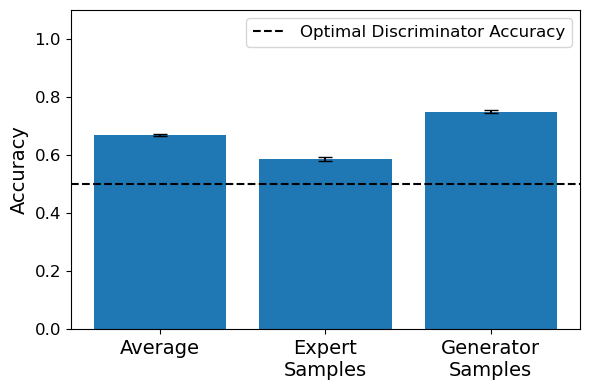

In [143]:
accuracy_desc = ["disc_acc", "disc_acc_expert", "disc_acc_gen"]
xticks = ["Average", "Expert\nSamples", "Generator\nSamples"]

accuracy_dic = {
    acc: df_models[acc] for acc in accuracy_desc
}
print(f"N={len(df_models)}")
acc_means = [accuracy_dic[a].mean() for a in accuracy_desc]
for i in range(3):
    print(f"{accuracy_desc[i]}={acc_means[i]:.4f}")

acc_stds = [accuracy_dic[a].std(ddof=0) for a in accuracy_desc]
acc_ns = [len(accuracy_dic[a]) for a in accuracy_desc]
acc_se = [std / np.sqrt(n) for std, n in zip(acc_stds, acc_ns)]

z = 1.96
acc_ci = [z * se for se in acc_se]

# plot
x = np.arange(len(accuracy_desc))
plt.figure(figsize=(6, 4))
plt.bar(x, acc_means, yerr=acc_ci, capsize=5)

optimal_level = 0.5
plt.axhline(optimal_level, linestyle="--", color="black", label="Optimal Discriminator Accuracy")

plt.xticks(x, xticks, fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.xlabel("")
plt.yticks(fontsize=12)
plt.ylim(0.0, 1.1)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

### Action prediction accuracy

- Check the mean accuracy of the five possible actions produced by the IRL.

In [144]:
# NOTHING = 0, UP = 1, DOWN = 2, RIGHT = 3, LEFT = 4
ACTION_REC_COLS = ["rec_noop", "rec_up", "rec_down", "rec_right", "rec_left"]
performance_cols = ["overall_accuracy"] + ACTION_REC_COLS
for col in performance_cols:
    if col not in df_models.columns:
        df_models[col] = np.nan

for idx, model in df_models.iterrows():
    subj_id = model["subj_id"]
    sample_type = model["sample_type"]
    rounds = model["rounds"]

In [145]:
csv_save_path = Path("irl_models/models_integrated.csv")
if csv_save_path.exists():
    df_models = pd.read_csv(csv_save_path)
else:
    for idx, model in df_models.iterrows():
        if all(pd.notna(model[col]) for col in performance_cols):
            continue
        accuracy_dict = calculate_action_prediction_performance(
            subjId=model["subj_id"],
            rounds=model["rounds"],
            web=model["sample_type"] == "web",
        )
        df_models.at[idx, "overall_accuracy"] = accuracy_dict["overall_accuracy"]
        for i in range(5):
            df_models.at[idx, ACTION_REC_COLS[i]] = accuracy_dict[f"action_{i}_recall"] if f"action_{i}_precision" in accuracy_dict else np.nan
        
    df_models.to_csv(csv_save_path, index=False)

df_models.head()

,subj_id,sample_type,rounds,disc_acc,disc_acc_expert,disc_acc_gen,overall_accuracy,rec_noop,rec_up,rec_down,rec_right,rec_left
0,904,desktop,11600,0.6426,0.5820,0.7031,0.715429,0.591757,0.879202,0.328947,0.673913,0.686869
1,1000,desktop,18980,0.6602,0.5469,0.7734,0.766950,0.636290,0.899705,0.291667,0.474820,0.527607
2,1001,desktop,18580,0.7285,0.6367,0.8203,0.802523,0.735010,0.901766,0.575342,0.278481,0.228070
3,1002,desktop,18080,0.6230,0.5508,0.6953,0.787503,0.642468,0.923732,0.225000,0.517647,0.459330
4,1003,desktop,18220,0.6582,0.6055,0.7109,0.768352,0.422222,0.934963,0.456522,0.598566,0.351598


overall_accuracy: 0.7468703418933428
rec_noop: mean=0.6284, ci=0.0156, n=282
rec_up: mean=0.8667, ci=0.0053, n=282
rec_down: mean=0.1918, ci=0.0205, n=280
rec_right: mean=0.5696, ci=0.0194, n=282
rec_left: mean=0.5612, ci=0.0196, n=282


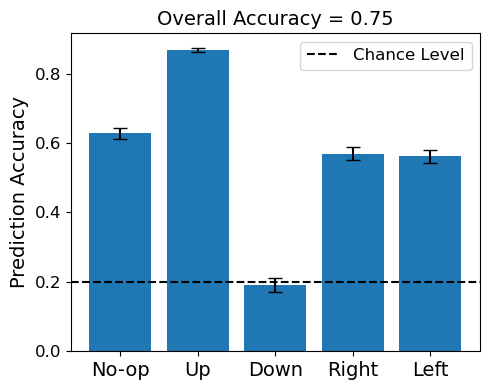

In [146]:
ACTION_LABELS = ["No-op", "Up", "Down", "Right", "Left"] # NOTHING = 0, UP = 1, DOWN = 2, RIGHT = 3, LEFT = 4

def plot_prediction_accuracy(
        dataframe,
        mean_col="overall_accuracy", # "weighted_f1", # "overall_accuracy"
        action_cols=ACTION_REC_COLS,
    ):
    overall_mean = dataframe[mean_col].mean()
    overall_std = dataframe[mean_col].std(ddof=0)
    print(f"{mean_col}: {overall_mean}")

    z = 1.96
    action_means = []
    # action_stds = []
    action_ns = []
    action_ci = []
    for col in action_cols:
        valid = dataframe[col].dropna()
        n = len(valid)

        mean = valid.mean()

        sd = valid.std(ddof=1)
        se = sd / np.sqrt(n)
        ci = t.ppf(0.975, df=n - 1) * se

        action_means.append(mean)
        # action_stds.append(std)
        action_ns.append(n)
        action_ci.append(ci)

        print(f"{col}: mean={mean:.4f}, ci={ci:.4f}, n={n}")

    x = np.arange(5)
    plt.figure(figsize=(5,4))
    plt.bar(x, action_means, yerr=action_ci, capsize=5)
    # add chance level
    chance_level = 1.0 / 5
    plt.axhline(chance_level, linestyle="--", color="black", label="Chance Level")

    plt.xticks(x, ACTION_LABELS, fontsize=14)
    plt.yticks(fontsize=12)
    # plt.ylabel("Recall", fontsize=14) 
    plt.ylabel("Prediction Accuracy", fontsize=14)
    # plt.xlabel("Action",fontsize=14)
    plt.title(
        f"{'Overall F1 Score' if mean_col == 'weighted_f1' else 'Overall Accuracy'} = {overall_mean:.2f}",
        fontsize=14,
    )

    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

plot_prediction_accuracy(dataframe=df_models, mean_col="overall_accuracy", action_cols=ACTION_REC_COLS)

### Action proportion

- Check the mean proportions of actions in the observed data and the action trajectories generated by the IRL agents.

In [147]:
ACTION_LABELS = ["No-op", "Up", "Down", "Right", "Left"]  # 0~4

num_actions = len(ACTION_LABELS)

obs_props_per_model = []
pred_props_per_model = []

for model in models:
    obs, actions, rewards, infos = load_connected_traj(
        model["subj_id"],
        web=model["sample_type"] == "web",
        remove_initial_noop=True,
    )
    reward_net, gen_algo = load_trained_model(
        subj_id = model["subj_id"], 
        train_rounds = model["rounds"], 
    )
    predicted_actions, _ = gen_algo.predict(obs, deterministic=True)
    predicted_actions = predicted_actions[:len(actions)]
    assert len(actions) == len(predicted_actions)

    actions = np.asarray(actions)
    predicted_actions = np.asarray(predicted_actions)

    counts_obs  = np.bincount(actions, minlength=num_actions)
    counts_pred = np.bincount(predicted_actions, minlength=num_actions)

    total = len(actions)
    obs_props_per_model.append(counts_obs  / total)
    pred_props_per_model.append(counts_pred / total)

obs_props_per_model  = np.vstack(obs_props_per_model)
pred_props_per_model = np.vstack(pred_props_per_model)

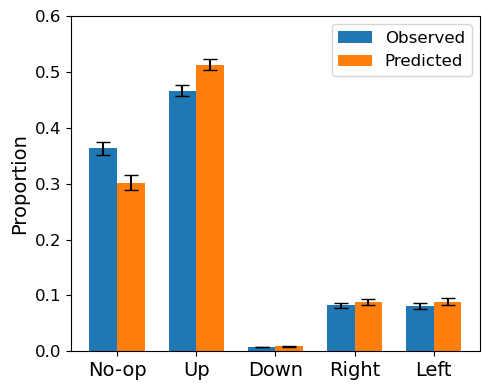

In [148]:
def plot_action_proportion(dataframe):
    obs_means  = obs_props_per_model.mean(axis=0)
    pred_means = pred_props_per_model.mean(axis=0)
    obs_stds = obs_props_per_model.std(axis=0, ddof=1)
    pred_stds = pred_props_per_model.std(axis=0, ddof=1)

    # 95% CI ≈ mean ± 1.96 * SE (N should be big enough)
    N = obs_props_per_model.shape[0]
    z = 1.96
    obs_se  = obs_stds / np.sqrt(N)
    pred_se = pred_stds / np.sqrt(N)
    obs_ci  = z * obs_se
    pred_ci = z * pred_se

    x = np.arange(num_actions)
    width = 0.35

    plt.figure(figsize=(5, 4))
    plt.bar(x - width/2, obs_means, width, yerr=obs_ci, capsize=5, label="Observed")
    plt.bar(x + width/2, pred_means, width, yerr=pred_ci, capsize=5, label="Predicted")

    plt.xticks(x, ACTION_LABELS,  fontsize=14)
    plt.yticks(fontsize=12)
    plt.ylabel("Proportion", fontsize=14)
    # plt.xlabel("Action", fontsize=14)
    plt.ylim(0, 0.6)
    # plt.title(f"Action distribution (N = {len(dataframe)})", fontsize=14)
    plt.legend(fontsize=12)
    plt.tight_layout()

plot_action_proportion(df_models)